# 02 - Machine learning pipeline: 90-day churn

**Problem.** Predict which customers active today will cancel in the next 90 days, so the retention team can call the riskiest first. **Target:** `1` if the subscription ends within 90 days after the snapshot date, else `0` (`sql/labels/churn_90d.sql`).

The pipeline is generic: the use case is a YAML file naming a feature SQL, a label SQL and business assumptions. This notebook walks through it step by step and then runs the packaged pipeline the app uses.

In [1]:
import os, sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
os.environ.setdefault("STORAGE_DIR", str(ROOT / "storage" / "notebooks"))  # isolated from the app database
os.environ.setdefault("LOG_LEVEL", "WARNING")
import warnings; warnings.filterwarnings("ignore")
import pandas as pd, matplotlib.pyplot as plt
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)

from insightforge.db import init_db, run_query, load_named_queries, load_sql
from insightforge.auth import sign_up, login, AuthError
from insightforge.ingest import load_synthetic, list_datasets, get_dataset
init_db()
try:
    user = login("notebook@kasatelecom.example", "Notebook#2026")
except AuthError:
    user = sign_up("Kasa Telecom", "Telecommunications", "Christokin Christopherson",
                   "notebook@kasatelecom.example", "Notebook#2026")
WS = user.workspace_id
ds = list_datasets(WS)
DATASET_ID = int(ds.iloc[0]["id"]) if not ds.empty else load_synthetic(WS, n_customers=8000, seed=42)
dataset = get_dataset(DATASET_ID, WS)
print(f"workspace {WS}, dataset {DATASET_ID}: {dataset['name']}")

workspace 1, dataset 1: Kasa Telecom synthetic (seed 42, 8,000 customers)


## 1. Use-case configuration

In [2]:
from insightforge.usecases import load_use_cases
ucs = load_use_cases()
uc = ucs["churn_90d"]
{k: v for k, v in uc.__dict__.items() if k != "feature_labels"}

{'id': 'churn_90d',
 'name': 'Customer churn (next 90 days)',
 'description': 'Predict which active customers will cancel their subscription within the next 90 days so the retention team can intervene before they leave.\n',
 'task_type': 'classification',
 'dataset_sources': ['synthetic_telco'],
 'features_sql': 'features/customer_snapshot_features.sql',
 'label_sql': 'labels/churn_90d.sql',
 'feature_transform': 'telco_customer',
 'horizon_days': 90,
 'positive_label': 'Cancels within 90 days',
 'outcome_noun': 'churn',
 'entity_label': 'customer',
 'n_train_snapshots': 4,
 'snapshot_step_months': 3,
 'value_column': 'monthly_fee',
 'value_label': 'Monthly fee (GHS)',
 'business': {'action': 'Retention call with a tailored offer',
  'target_top_pct': 0.15,
  'contact_cost_ghs': 15,
  'offer_cost_ghs': 60,
  'save_rate': 0.3,
  'value_months': 12},
 'custom_table': None,
 'target_column': None,
 'id_column': None}

## 2. Point-in-time snapshots and out-of-time validation

Features use only data available on the snapshot date. We train on four earlier quarterly snapshots and test on the most recent snapshot whose 90-day outcome is fully observed. This mimics production (train on the past, predict the future) and is stricter than a random split.

In [3]:
from insightforge.analysis import to_date
from insightforge.ml.pipeline import plan_snapshots, build_snapshot_frame
train_snaps, test_snap, score_snap = plan_snapshots(uc, to_date(dataset["as_of_date"]))
print("train:", train_snaps, "\ntest:", test_snap, "\nscore (no labels yet):", score_snap)

train: [datetime.date(2025, 6, 30), datetime.date(2025, 9, 30), datetime.date(2025, 12, 31), datetime.date(2026, 3, 31)] 
test: 2026-06-30 
score (no labels yet): 2026-09-30


## 3. Feature extraction in SQL

CTEs aggregate usage, payments and tickets per customer over trailing windows; a `ROW_NUMBER()` window picks the latest month; conditional aggregation splits windows.

In [4]:
print(load_sql(uc.features_sql)[:2500], "...")

WITH active AS (
    SELECT s.workspace_id, s.subscription_id, s.customer_id, s.plan_id,
           s.start_date, s.contract_type, s.autopay
    FROM v_subscriptions_clean s
    WHERE s.workspace_id = :ws
      AND s.start_date <= :snapshot
      AND (s.end_date IS NULL OR s.end_date > :snapshot)
),
usage_win AS (
    SELECT u.subscription_id,
           AVG(CASE WHEN u.usage_month >= :m3_start THEN u.data_gb_used END)                                   AS data_gb_avg_3m,
           AVG(CASE WHEN u.usage_month < :m3_start THEN u.data_gb_used END)                                    AS data_gb_avg_prev3m,
           AVG(CASE WHEN u.usage_month >= :m3_start THEN u.voice_minutes END)                                  AS voice_min_avg_3m,
           AVG(CASE WHEN u.usage_month < :m3_start THEN u.voice_minutes END)                                   AS voice_min_avg_prev3m,
           AVG(CASE WHEN u.usage_month >= :m3_start THEN u.sms_count END)                                      AS sms_avg_

In [5]:
train_df = pd.concat([build_snapshot_frame(uc, WS, s) for s in train_snaps], ignore_index=True)
test_df = build_snapshot_frame(uc, WS, test_snap)
print(train_df.shape, test_df.shape)
print("churn rate - train: %.2f%%, test: %.2f%%" % (100 * train_df.target.mean(), 100 * test_df.target.mean()))
train_df.head()

(14727, 34) (4076, 34)
churn rate - train: 8.48%, test: 6.84%


,entity_id,region,segment,acquisition_channel,contract_type,autopay,plan_type,monthly_fee,plan_data_gb,data_gb_avg_3m,data_gb_avg_prev3m,data_gb_last_month,voice_min_avg_3m,voice_min_avg_prev3m,sms_avg_3m,...,unpaid_bills_3m,tickets_90d,network_tickets_90d,billing_tickets_90d,low_csat_tickets_90d,avg_csat_90d,avg_resolution_hours_90d,tenure_months,age,data_usage_trend,voice_usage_trend,data_utilisation,last_month_vs_avg,target,snapshot_date
0,C00003,Unknown,SME,Online,24-month,1,Fibre,380.0,500.0,486.336667,543.286667,529.45,218.066667,221.433333,21.000000,...,1,0,0,0,0,NaN,NaN,13.3,48.0,0.895175,0.984796,0.972673,1.088649,0,2025-06-30
1,C00006,Ashanti,SME,Retail Shop,Month-to-month,0,Fibre,550.0,1000.0,992.693333,886.910000,862.97,219.000000,193.900000,9.666667,...,0,1,1,0,1,2.0,195.40,22.5,43.0,1.119272,1.129448,0.992693,0.869322,0,2025-06-30
2,C00010,Greater Accra,Consumer,Agent,Month-to-month,1,Postpaid,320.0,150.0,138.186667,141.270000,123.07,118.833333,141.266667,16.000000,...,0,2,2,0,0,NaN,22.45,9.9,29.0,0.978174,0.841199,0.921244,0.890607,0,2025-06-30
3,C00013,Northern,Consumer,Online,Month-to-month,1,Prepaid,69.0,12.0,7.466667,6.116667,8.24,389.133333,476.233333,35.000000,...,0,1,1,0,0,4.0,21.20,19.6,NaN,1.220708,0.817106,0.622222,1.103571,0,2025-06-30
4,C00014,Ashanti,Consumer,Retail Shop,12-month,0,Postpaid,199.0,50.0,18.770000,15.345000,12.51,130.833333,314.950000,21.000000,...,0,0,0,0,0,NaN,NaN,4.2,34.0,1.223200,0.415410,0.375400,0.666489,1,2025-06-30


Python then derives point-in-time features (`insightforge/ml/features.py`): tenure and age at the snapshot, usage trends (last 3 months / prior 3 months), allowance utilisation and last month vs average.

In [6]:
train_df[["tenure_months", "data_usage_trend", "voice_usage_trend", "data_utilisation", "last_month_vs_avg"]].describe().T

,count,mean,std,min,25%,50%,75%,max
tenure_months,14727.0,18.201636,12.405373,0.100000,6.600000,16.600000,29.700000,38.900000
data_usage_trend,12873.0,1.010472,0.192072,0.448509,0.876093,0.993990,1.127752,1.938489
voice_usage_trend,12876.0,1.017234,0.226741,0.346809,0.856094,0.993399,1.153644,2.415884
data_utilisation,14719.0,0.670903,0.227987,0.050400,0.507333,0.666000,0.827500,1.591733
last_month_vs_avg,14589.0,0.991695,0.173964,0.380894,0.876257,0.997990,1.098787,1.807157


## 4. Preprocessing and candidate models

* Numeric: median imputation **with missing-value indicators**, then scaling.
* Categorical: 'Unknown' for missing, one-hot with rare categories pooled.
* Candidates: a no-skill **baseline**, **logistic regression** (interpretable), **random forest**, **gradient boosting**.
* Selection metric: **PR-AUC**, because churners are a small minority (~7%) and we care about ranking the riskiest correctly. We also report ROC-AUC, Brier score, and reach/lift at the team's capacity (top 15%).

In [7]:
from insightforge.ml.pipeline import train_use_case
out = train_use_case(WS, DATASET_ID, uc, progress=print)
d = out.details
pd.DataFrame(d["comparison"])[["model", "roc_auc", "pr_auc", "recall_at_top", "precision_at_top", "lift_at_top", "brier", "fit_seconds"]].round(3)

Extracting features with SQL for 6 snapshots


Training Baseline (base rate)


Training Logistic regression


Training Random forest


Training Gradient boosting


Explaining model drivers


Refitting on all labelled data and scoring


,model,roc_auc,pr_auc,recall_at_top,precision_at_top,lift_at_top,brier,fit_seconds
0,Baseline (base rate),0.500,0.068,0.168,0.077,1.124,0.064,0.21
1,Logistic regression,0.765,0.307,0.516,0.236,3.443,0.056,0.97
2,Random forest,0.773,0.313,0.505,0.231,3.371,0.057,3.81
3,Gradient boosting,0.780,0.340,0.541,0.247,3.610,0.054,0.75


**Reading the comparison.** All three learned models beat the baseline by a wide margin and are close to each other; gradient boosting wins narrowly on PR-AUC. Logistic regression is almost as good, which is a useful fallback if explainability or simplicity were the priority.

## 5. How useful is it? Lift and capture

In [8]:
lift = pd.DataFrame(d["lift_table"]); lift[["decile", "customers", "positives", "actual_rate", "cum_capture", "lift"]].round(3)

,decile,customers,positives,actual_rate,cum_capture,lift
0,1,408,121,0.297,0.434,4.333
1,2,408,45,0.110,0.595,1.611
2,3,407,22,0.054,0.674,0.790
3,4,408,30,0.074,0.781,1.074
4,5,407,13,0.032,0.828,0.467
5,6,408,15,0.037,0.882,0.537
6,7,408,6,0.015,0.903,0.215
7,8,407,12,0.029,0.946,0.431
8,9,408,11,0.027,0.986,0.394
9,10,407,4,0.010,1.000,0.144


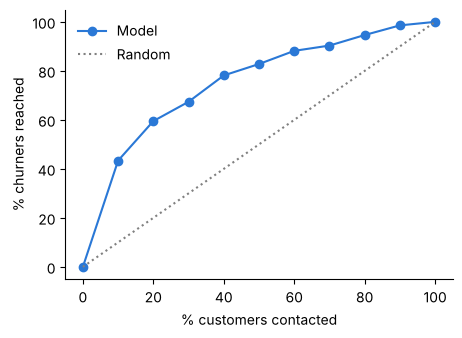

In [9]:
fig, ax = plt.subplots(figsize=(5, 3.5))
ax.plot([0] + list(lift.decile * 10), [0] + list(lift.cum_capture * 100), marker="o", color="#2a78d6", label="Model")
ax.plot([0, 100], [0, 100], ls=":", color="grey", label="Random")
ax.set_xlabel("% customers contacted"); ax.set_ylabel("% churners reached"); ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False); plt.show()

## 6. Drivers (permutation importance on the test set)

In [10]:
drv = pd.DataFrame(d["drivers"])[["label", "importance", "importance_std", "direction", "risky_categories"]]
drv.head(12).round(4)

,label,importance,importance_std,direction,risky_categories
0,Voice use trend (last 3m / prior 3m),0.0943,0.0088,lower,NaN
1,Data use trend (last 3m / prior 3m),0.0742,0.0117,lower,NaN
2,Last month vs 3-month average data use,0.0684,0.0119,lower,NaN
3,Contract type,0.0661,0.0206,category,[Month-to-month]
4,Tenure (months),0.0237,0.0067,lower,NaN
5,"Avg SMS, last 3 months",0.0188,0.0014,lower,NaN
6,Autopay enabled,0.0162,0.0083,lower,NaN
7,"Avg voice minutes, last 3 months",0.0138,0.0044,lower,NaN
8,Share of data allowance used,0.0118,0.0071,lower,NaN
9,"Data use, last month (GB)",0.0034,0.0031,lower,NaN


**Business interpretation.** The strongest signals are **behavioural**: customers whose voice and data use is falling relative to their own history are disengaging before they leave. **Contract type** is the main structural driver (month-to-month is riskiest), followed by **short tenure** and **no autopay**. Implications: (1) usage decline should trigger an automatic re-engagement offer and a network check, (2) migrate month-to-month customers to commitment plans, (3) invest in the first months of the customer lifecycle, (4) push autopay enrolment. Importance measures what the model relies on - it is association, not proof of cause.

## 7. Business value at the team's capacity

In [11]:
d["campaign_simulation"]

{'population': 4076,
 'contacted': 611,
 'positives_in_population': 279,
 'positives_reached_model': 151,
 'positives_reached_random': 41.9,
 'customers_saved_model': 45.3,
 'customers_saved_random': 12.6,
 'avg_monthly_value_reached': 96.7,
 'revenue_protected_model_ghs': 52567.0,
 'campaign_cost_model_ghs': 11883.0,
 'net_benefit_model_ghs': 40684.0,
 'revenue_protected_random_ghs': 14569.0,
 'net_benefit_random_ghs': 4651.0,
 'roi_model': 3.42,
 'assumptions': {'action': 'Retention call with a tailored offer',
  'target_top_pct': 0.15,
  'contact_cost_ghs': 15,
  'offer_cost_ghs': 60,
  'save_rate': 0.3,
  'value_months': 12}}

Under the stated assumptions (15% of customers contacted, GHS 15 per call, GHS 60 incentive, 30% save rate, 12-month value) model targeting returns several times the net benefit of random targeting. The assumptions live in the use-case YAML and should be calibrated with a control-group pilot.

## 8. Scoring today's base

In [12]:
print({k: v for k, v in d["scoring_summary"].items() if k != "tiers"})
pd.DataFrame(d["scoring_summary"]["tiers"])

{'population': 4173, 'expected_positives': 275.91684, 'expected_rate': 0.06612, 'expected_value_at_risk_ghs': 424216.354932, 'value_months': 12, 'high_tier_value_at_risk_ghs': 102744.91081}


,risk_tier,customers,avg_score,expected_positives,monthly_value
0,High,417,0.228511,95.289226,39365.0
1,Low,2922,0.035352,103.298371,594688.0
2,Medium,834,0.092721,77.329244,87872.0


In [13]:
out.scored.head(10)

,entity_id,score,value,risk_tier,top_reasons
0,C02081,0.883313,69.0,High,Voice use trend (last 3m / prior 3m): 0.70 (lo...
1,C06546,0.778507,40.0,High,Voice use trend (last 3m / prior 3m): 0.70 (lo...
2,C04737,0.684097,115.0,High,Voice use trend (last 3m / prior 3m): 0.66 (lo...
3,C07388,0.681649,40.0,High,Voice use trend (last 3m / prior 3m): 0.77 (lo...
4,C06370,0.664863,199.0,High,Last month vs 3-month average data use: 0.72 (...
5,C04518,0.647223,69.0,High,Voice use trend (last 3m / prior 3m): 0.76 (lo...
6,C02519,0.556510,69.0,High,Voice use trend (last 3m / prior 3m): 0.74 (lo...
7,C01168,0.534618,69.0,High,Voice use trend (last 3m / prior 3m): 0.66 (lo...
8,C06241,0.531901,40.0,High,Data use trend (last 3m / prior 3m): 0.68 (low...
9,C03668,0.518847,69.0,High,Voice use trend (last 3m / prior 3m): 0.77 (lo...


## 9. Monitoring baseline: drift (PSI)

PSI compares the scoring population with the training population: <0.1 stable, 0.1-0.25 watch, >0.25 drift.

In [14]:
print(d["score_drift"])
pd.DataFrame(d["drift"]).head(8)

{'psi': 0.02107, 'status': 'stable', 'mean_reference': 0.08164, 'mean_current': 0.06612}


,feature,psi,status,missing_pct_reference,missing_pct_current
0,tenure_months,0.2518,drift,0.00,0.00
1,last_month_vs_avg,0.0408,stable,0.88,0.81
2,bills_6m,0.0273,stable,0.00,0.00
3,unpaid_bills_3m,0.0083,stable,0.00,0.00
4,avg_resolution_hours_90d,0.0081,stable,56.00,56.60
5,dropped_calls_3m,0.0063,stable,0.00,0.00
6,unpaid_bills_6m,0.0056,stable,0.00,0.00
7,data_utilisation,0.0055,stable,0.04,0.00


Tenure shows drift because the customer base has aged since the earliest training snapshot - expected, but it is exactly what monitoring should surface. In production this check runs at every scoring; when outcomes arrive 90 days later we recompute PR-AUC and calibration and retrain if performance drops more than 15% or a key feature drifts (PSI > 0.25).

## 10. Same pipeline, different business problem

The payment-delinquency use case reuses the feature SQL and only swaps the label SQL - no code changes.

In [15]:
out2 = train_use_case(WS, DATASET_ID, ucs["payment_delinquency_90d"])
pd.DataFrame(out2.details["comparison"])[["model", "roc_auc", "pr_auc", "lift_at_top"]].round(3)

,model,roc_auc,pr_auc,lift_at_top
0,Baseline (base rate),0.500,0.305,0.991
1,Logistic regression,0.698,0.475,1.609
2,Random forest,0.697,0.471,1.609
3,Gradient boosting,0.698,0.477,1.586


In [16]:
pd.DataFrame(out2.details["drivers"])[["label", "importance", "direction"]].head(6).round(4)

,label,importance,direction
0,Autopay enabled,0.1127,lower
1,"Late payments, last 6 months",0.0148,higher
2,"Missed bills, last 6 months",0.0123,higher
3,Voice min avg prev3m,0.0052,lower
4,Data usage trend,0.0041,higher
5,"Missed bills, last 3 months",0.0033,higher


Here autopay and recent missed bills dominate - a different set of drivers for a different decision (collections rather than retention), produced by the same platform.